# 03 · Consistency across years, and the 2025 check

**EDA Steps 6–7.**

* **Step 6:** Are the Feb vs Dec differences the same in 2022, 2023 and 2024? Headline numbers come from the **full data**; the breakdowns come from the sample.
* **Step 7:** How does 2025 compare with 2022–2024? This tells you how much to trust a model tested on 2025. No modeling here.

📊 marks cells that make a chart.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import taxi_utils as tu

tu.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
MEANINGFUL_GAP = 0.5
MONTHS2 = ["Feb", "Dec"]
YEARS = tu.EDA_YEARS
ALL_YEARS = YEARS + [tu.TEST_YEAR]

sample = pd.concat([pd.read_parquet(tu.SAMPLE / f"sample_{m}.parquet") for m in tu.MONTHS],
                   ignore_index=True)
full_month = pd.read_csv(tu.PROCESSED / "full_by_month.csv")
full_hour = pd.read_csv(tu.PROCESSED / "full_by_hour.csv")
full_zone = pd.read_csv(tu.PROCESSED / "full_by_zone.csv")
full_borough = pd.read_csv(tu.PROCESSED / "full_by_borough.csv")
full_cbd = pd.read_csv(tu.PROCESSED / "full_by_cbd_2025.csv")

---
# Step 6 · Consistency across 2022–2024
## 6a · The Dec − Feb gap each year 📊 (full data)

$$\Delta_y = \overline{\text{tip\%}}_{\text{Dec},\,y} - \overline{\text{tip\%}}_{\text{Feb},\,y}$$

The same gap is also computed for the zero-tip share and the share tipping 20% or more. Error bars are 95% CIs. If the dots sit on the same side of zero every year, the pattern is consistent.

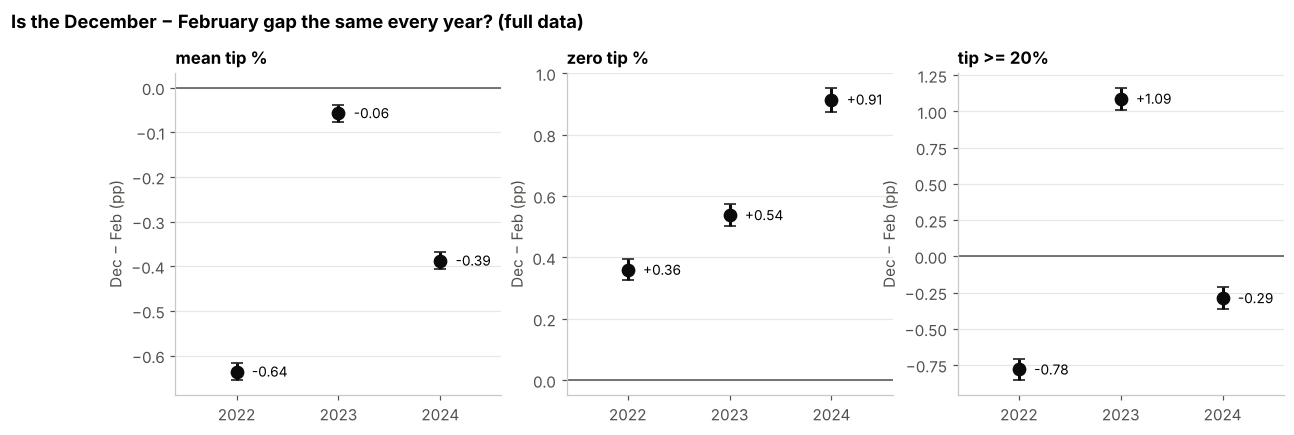

year,2022,2023,2024
metric,,,
mean tip %,-0.64,-0.06,-0.39
zero tip %,0.36,0.54,0.91
tip >= 20%,-0.78,1.09,-0.29


In [2]:
def gap_table(fm):
    rows = []
    for y, g in fm.groupby("year"):
        f, d = g[g.month_name == "Feb"].iloc[0], g[g.month_name == "Dec"].iloc[0]
        se_mean = np.sqrt(f.sd**2 / f.n + d.sd**2 / d.n)
        for metric, pf, pd_ in [("zero tip %", f.zero_tip_pct, d.zero_tip_pct),
                                ("tip >= 20%", f.tip20_pct, d.tip20_pct)]:
            se = np.sqrt(pf * (100 - pf) / f.n + pd_ * (100 - pd_) / d.n)
            rows.append({"year": y, "metric": metric, "Feb": pf, "Dec": pd_, "gap": pd_ - pf, "ci95": 1.96 * se})
        rows.append({"year": y, "metric": "mean tip %", "Feb": f["mean"], "Dec": d["mean"],
                     "gap": d["mean"] - f["mean"], "ci95": 1.96 * se_mean})
    return pd.DataFrame(rows)

gaps = gap_table(full_month)
metrics = ["mean tip %", "zero tip %", "tip >= 20%"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, met in zip(axes, metrics):
    d = gaps[(gaps.metric == met) & gaps.year.isin(YEARS)]
    ax.axhline(0, color=tu.INK_2, linewidth=1)
    ax.errorbar(d.year.astype(str), d.gap, yerr=d.ci95, fmt="o", color=tu.INK, markersize=8, capsize=4)
    for x, v in zip(d.year.astype(str), d.gap):
        ax.annotate(f"{v:+.2f}", (x, v), textcoords="offset points", xytext=(10, 0), va="center", fontsize=9)
    ax.set_title(met, fontsize=11)
    ax.set_ylabel("Dec − Feb (pp)")
    ax.margins(x=0.3)
fig.suptitle("Is the December − February gap the same every year? (full data)",
             x=0.01, ha="left", fontweight="bold", y=1.03)
tu.save_fig(fig, "06a_gap_by_year")
plt.show()
gaps[gaps.year.isin(YEARS)].pivot(index="metric", columns="year", values="gap").loc[metrics]

## 6b · Key metrics by year 📊 (full data)

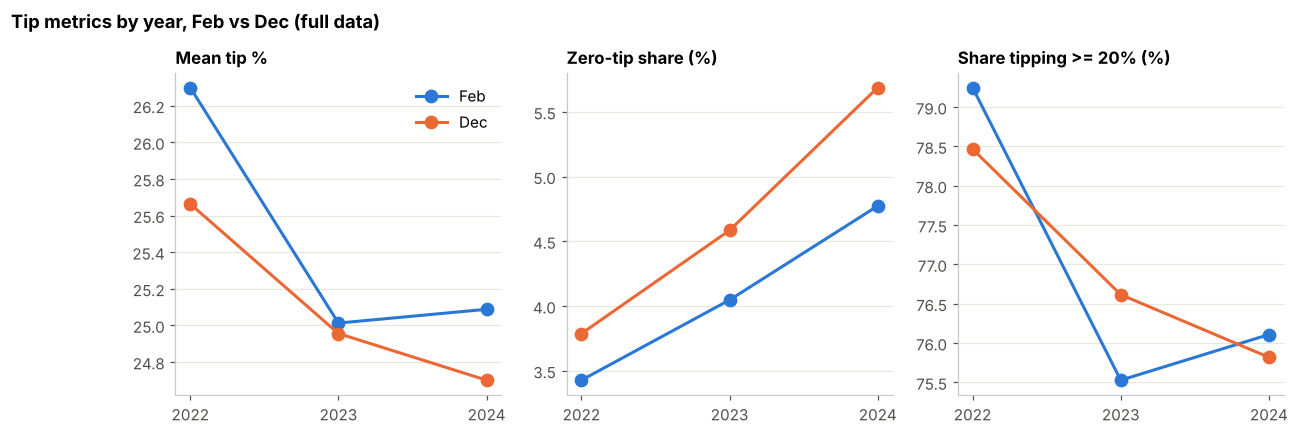

In [3]:
fm = full_month[full_month.year.isin(YEARS)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, title in [(axes[0], "mean", "Mean tip %"), (axes[1], "zero_tip_pct", "Zero-tip share (%)"),
                       (axes[2], "tip20_pct", "Share tipping >= 20% (%)")]:
    for mn in MONTHS2:
        d = fm[fm.month_name == mn]
        ax.plot(d.year.astype(str), d[col], marker="o", markersize=8, color=tu.MONTH_COLORS[mn], label=mn)
    ax.set_title(title, fontsize=11)
axes[0].legend()
fig.suptitle("Tip metrics by year, Feb vs Dec (full data)", x=0.01, ha="left", fontweight="bold", y=1.03)
tu.save_fig(fig, "06b_metrics_by_year")
plt.show()

## 6c · Tip % by hour, one panel per year 📊 (full data)

If the three panels look alike, the hourly pattern (and the Feb vs Dec gap within it) is stable.

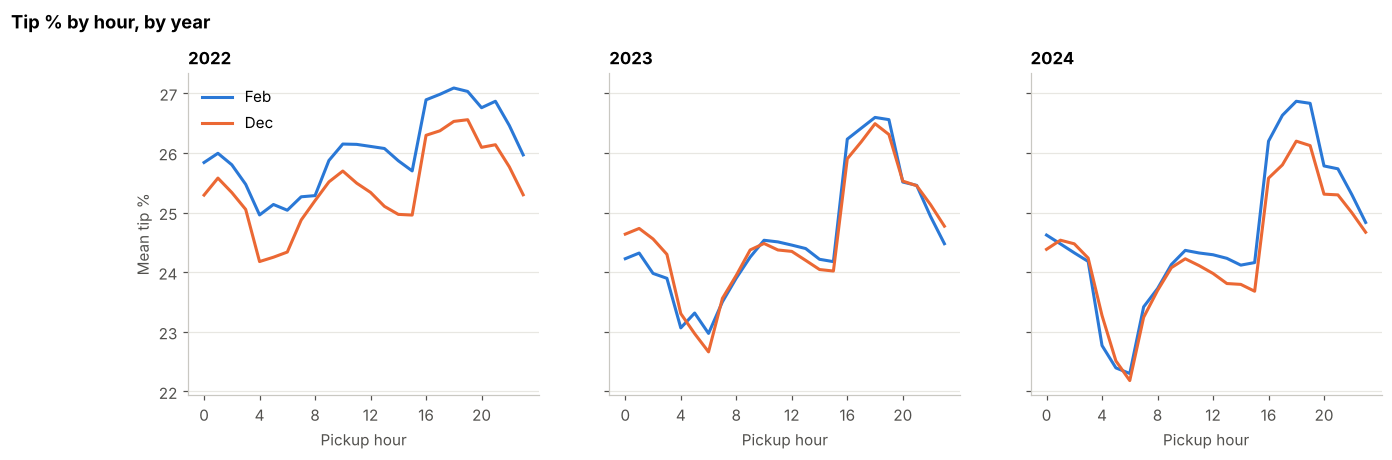

year            2022      2023      2024     
month_name       Dec  Feb  Dec  Feb  Dec  Feb
year month_name                              
2022 Dec        1.00 0.95 0.97 0.95 0.95 0.96
     Feb        0.95 1.00 0.95 0.97 0.93 0.96
2023 Dec        0.97 0.95 1.00 0.97 0.99 0.99
     Feb        0.95 0.97 0.97 1.00 0.94 0.98
2024 Dec        0.95 0.93 0.99 0.94 1.00 0.98
     Feb        0.96 0.96 0.99 0.98 0.98 1.00

In [4]:
fh = full_hour[full_hour.year.isin(YEARS)]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, y in zip(axes, YEARS):
    for mn in MONTHS2:
        d = fh[(fh.year == y) & (fh.month_name == mn)]
        ax.plot(d.hour, d["mean"], color=tu.MONTH_COLORS[mn], label=mn)
    ax.set_title(str(y), fontsize=11)
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlabel("Pickup hour")
axes[0].set_ylabel("Mean tip %")
axes[0].legend()
fig.suptitle("Tip % by hour, by year", x=0.01, ha="left", fontweight="bold", y=1.03)
tu.save_fig(fig, "06c_tip_by_hour_by_year")
plt.show()

# How similar are the hourly profiles between years? (correlation of the 24 hourly means)
prof = fh.pivot_table(index="hour", columns=["year", "month_name"], values="mean")
prof.corr().round(2)

## 6d · Tip % by borough, one panel per year 📊 (full data)

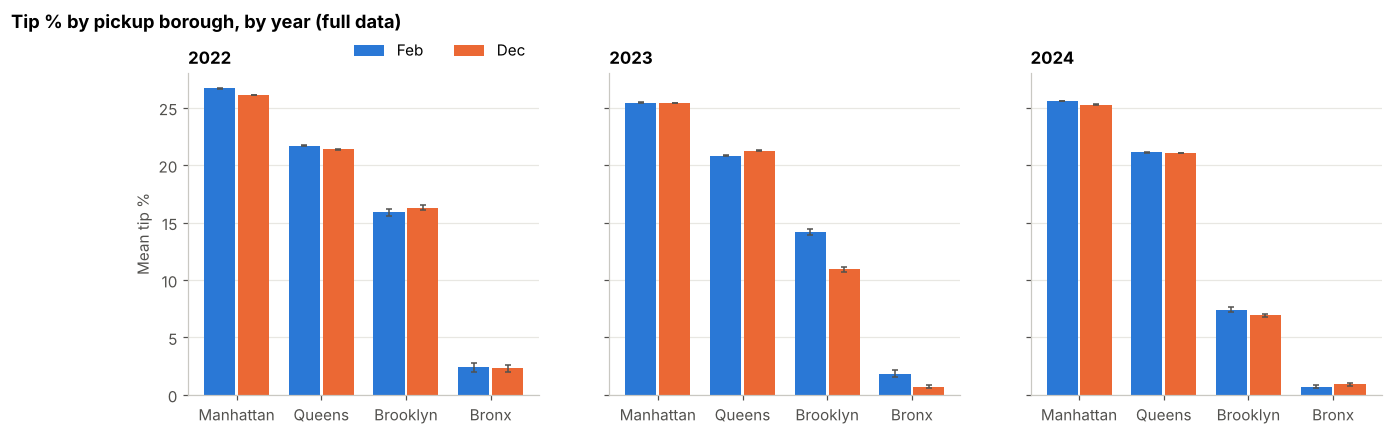

year        2022        2023        2024      
month_name   Dec   Feb   Dec   Feb   Dec   Feb
pu_borough                                    
Manhattan  26.14 26.68 25.42 25.45 25.28 25.61
Queens     21.39 21.69 21.25 20.82 21.06 21.13
Brooklyn   16.31 15.89 10.93 14.21  6.92  7.43
Bronx       2.30  2.40  0.70  1.84  0.91  0.69

In [5]:
fb = full_borough[full_borough.year.isin(YEARS) & full_borough.pu_borough.isin(["Manhattan", "Queens", "Brooklyn", "Bronx"])]
order = ["Manhattan", "Queens", "Brooklyn", "Bronx"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, y in zip(axes, YEARS):
    tu.grouped_bar(ax, fb[fb.year == y], "pu_borough", "month_name", "mean", tu.MONTH_COLORS,
                   err="ci95", order=order, groups=MONTHS2)
    ax.set_title(str(y), fontsize=11)
    if y != YEARS[0]:
        ax.get_legend().remove()
axes[0].set_ylabel("Mean tip %")
fig.suptitle("Tip % by pickup borough, by year (full data)", x=0.01, ha="left", fontweight="bold", y=1.03)
tu.save_fig(fig, "06d_tip_by_borough_by_year")
plt.show()
fb.pivot_table(index="pu_borough", columns=["year", "month_name"], values="mean").loc[order]

## 6e · Do the same zones tip high every year? 📊 (full data)

Each zone's mean tip % per year (Feb + Dec combined), for zones with at least 1,000 trips in every year. Spearman's rank correlation near 1 means the ranking of zones is stable.

72 zones have at least 1,000 trips in every year


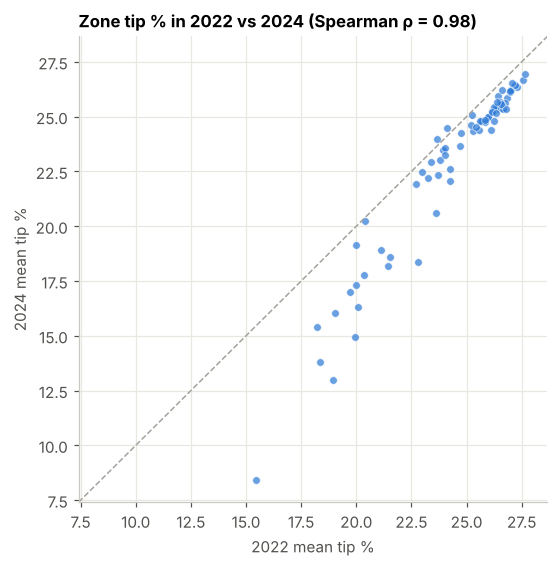

,2022,2023,2024,2025
2022,1.00,0.99,0.98,0.98
2023,0.99,1.00,0.99,0.98
2024,0.98,0.99,1.00,0.98
2025,0.98,0.98,0.98,1.00


In [6]:
z = full_zone.copy()
z["tip_sum"] = z["mean"] * z.n
zy = z.groupby(["year", "PULocationID", "pu_zone"])[["n", "tip_sum"]].sum().reset_index()
zy["mean"] = zy.tip_sum / zy.n
zw = zy.pivot_table(index=["PULocationID", "pu_zone"], columns="year", values=["mean", "n"])
ok = (zw["n"][ALL_YEARS] >= 1000).all(axis=1)
zm = zw["mean"][ok]
print(f"{ok.sum()} zones have at least 1,000 trips in every year")

rho = pd.DataFrame(index=ALL_YEARS, columns=ALL_YEARS, dtype=float)
for a in ALL_YEARS:
    for b in ALL_YEARS:
        rho.loc[a, b] = spearmanr(zm[a], zm[b]).statistic
rho.to_csv(tu.DOCS / "step6_zone_rank_correlation.csv")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(zm[2022], zm[2024], s=25, color=tu.FEB, alpha=0.7, edgecolor="white", linewidth=0.5)
lo, hi = zm[[2022, 2024]].min().min() - 1, zm[[2022, 2024]].max().max() + 1
ax.plot([lo, hi], [lo, hi], color=tu.NEUTRAL, linestyle="--", linewidth=1)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("2022 mean tip %")
ax.set_ylabel("2024 mean tip %")
ax.grid(axis="x")
ax.set_title(f"Zone tip % in 2022 vs 2024 (Spearman ρ = {rho.loc[2022, 2024]:.2f})", fontsize=11)
tu.save_fig(fig, "06e_zone_2022_vs_2024")
plt.show()
rho.round(2)

## 6f · Stability checklist (sample)

For each breakdown, the Dec − Feb gap in mean tip % is computed separately for each year. A pattern is **stable** if the gap has the same sign in all three years. `range` is how much the gap moves between years.

In [7]:
def yearly_gaps(df, col=None, label="overall"):
    rows = []
    groups = [("All trips", df)] if col is None else list(df.groupby(col, observed=True))
    for lvl, g in groups:
        r = {"dimension": label, "level": str(lvl)}
        for y in YEARS:
            gy = g[g.year == y]
            f, d = gy[gy.month_name == "Feb"].tip_pct, gy[gy.month_name == "Dec"].tip_pct
            r[y] = d.mean() - f.mean() if min(len(f), len(d)) >= 500 else np.nan
        rows.append(r)
    return rows

s = sample[sample.year.isin(YEARS)]
rows = yearly_gaps(s)
for label, col in [("borough", "pu_borough"), ("airport trip", "is_airport"), ("distance", "dist_bucket"),
                   ("weekend", "is_weekend"), ("night (10pm-6am)", "is_night"), ("holiday period", "is_holiday")]:
    rows += yearly_gaps(s, col, label)
check = pd.DataFrame(rows).dropna(subset=YEARS)
signs = np.sign(check[YEARS])
check["same sign all years"] = signs.nunique(axis=1) == 1
check["range"] = check[YEARS].max(axis=1) - check[YEARS].min(axis=1)
check["any year meaningful"] = (check[YEARS].abs() >= MEANINGFUL_GAP).any(axis=1)
check.to_csv(tu.DOCS / "step6_stability_checklist.csv", index=False)
check.set_index(["dimension", "level"])

2022  2023  2024  same sign all years  range  \
dimension        level                                                     
overall          All trips -0.64 -0.06 -0.38                 True   0.57   
borough          Brooklyn   0.39 -3.12 -0.73                False   3.51   
                 Manhattan -0.54 -0.03 -0.32                 True   0.51   
                 Queens    -0.20  0.38 -0.12                False   0.58   
airport trip     False     -0.52 -0.09 -0.35                 True   0.43   
                 True      -0.21  0.47 -0.22                False   0.69   
distance         0-1       -0.77 -0.71 -0.77                 True   0.06   
                 1-3       -0.54 -0.20 -0.41                 True   0.34   
                 3-7       -0.18  0.07 -0.08                False   0.25   
                 7-15       0.28  0.25 -0.34                False   0.62   
                 15+       -0.26  0.36 -0.10                False   0.61   
weekend          False     -0.77 -0.15 -0.36                 True   0.62   
                 True      -0.33  0.25 -0.38                False   0.64   
night (10pm-6am) False     -0.65 -0.11 -0.42                 True   0.54   
                 True      -0.56  0.20 -0.16                False   0.76   
holiday period   False     -0.53 -0.17 -0.49                 True   0.36   
                 True      -1.03  0.76  0.37                False   1.79   

                            any year meaningful  
dimension        level                           
overall          All trips                 True  
borough          Brooklyn                  True  
                 Manhattan                 True  
                 Queens                   False  
airport trip     False                     True  
                 True                     False  
distance         0-1                       True  
                 1-3                       True  
                 3-7                      False  
                 7-15                     False  
                 15+                      False  
weekend          False                     True  
                 True                     False  
night (10pm-6am) False                     True  
                 True                      True  
holiday period   False                     True  
                 True                      True

---
# Step 7 · How 2025 compares
## 7a · 2025 vs 2022–2024 on key metrics 📊 (full data)

The shaded column is 2025.

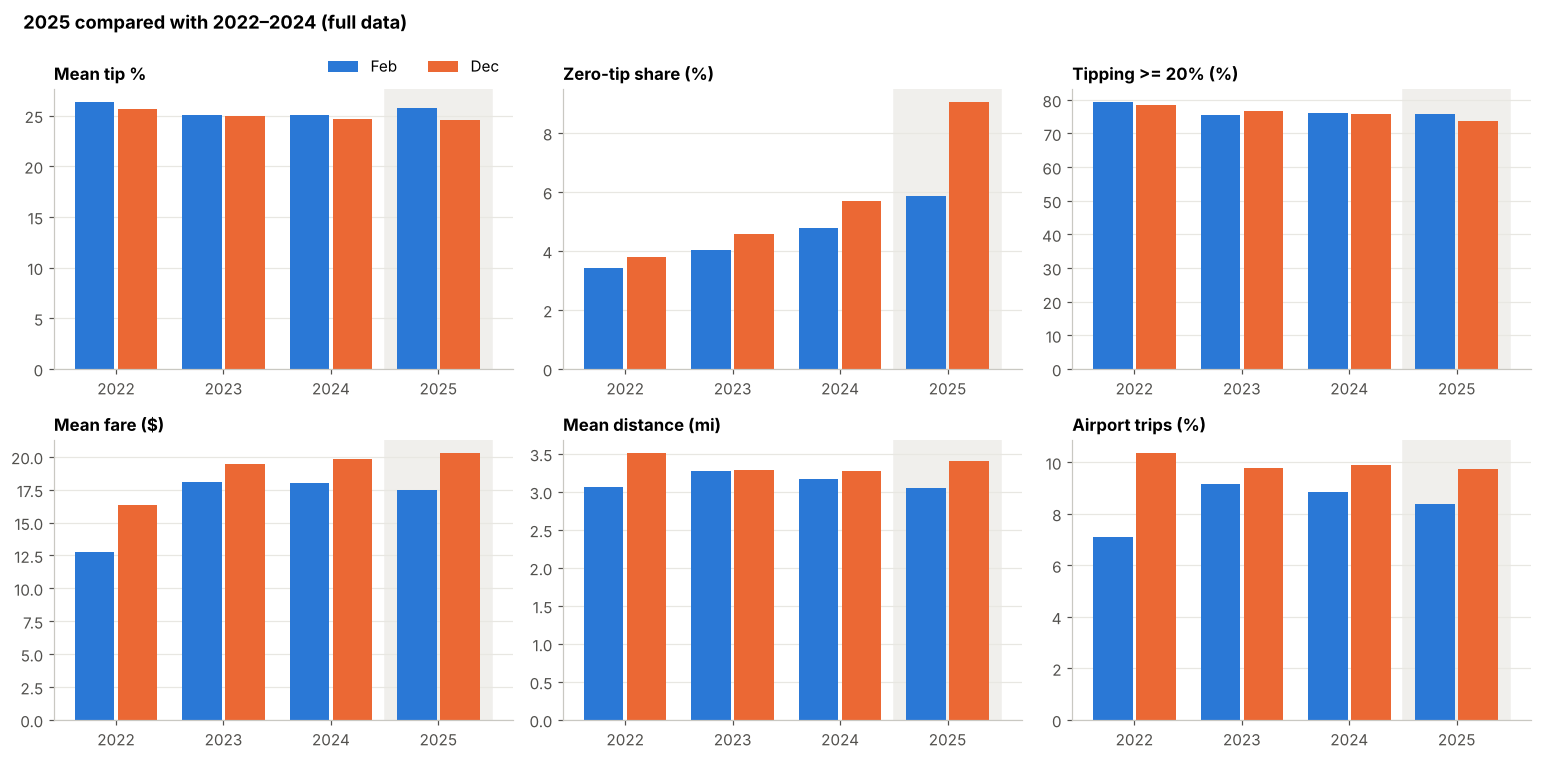

month_name                         Feb   Dec
2022-24 average    mean          25.47 25.11
                   zero_tip_pct   4.08  4.69
                   tip20_pct     76.96 76.97
                   mean_fare     16.30 18.53
                   mean_distance  3.17  3.35
                   airport_share  8.38 10.00
2025               mean          25.70 24.58
                   zero_tip_pct   5.88  9.04
                   tip20_pct     75.76 73.79
                   mean_fare     17.46 20.26
                   mean_distance  3.05  3.41
                   airport_share  8.39  9.73
2025 minus average mean           0.24 -0.53
                   zero_tip_pct   1.79  4.35
                   tip20_pct     -1.20 -3.17
                   mean_fare      1.17  1.73
                   mean_distance -0.12  0.05
                   airport_share  0.01 -0.28

In [8]:
panels = [("mean", "Mean tip %"), ("zero_tip_pct", "Zero-tip share (%)"), ("tip20_pct", "Tipping >= 20% (%)"),
          ("mean_fare", "Mean fare ($)"), ("mean_distance", "Mean distance (mi)"), ("airport_share", "Airport trips (%)")]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, title) in zip(axes.flat, panels):
    tu.grouped_bar(ax, full_month, "year", "month_name", col, tu.MONTH_COLORS,
                   order=ALL_YEARS, groups=MONTHS2)
    ax.axvspan(2.5, 3.5, color="#f0efec", zorder=0)
    ax.set_title(title, fontsize=11)
    if col != "mean":
        ax.get_legend().remove()
fig.suptitle("2025 compared with 2022–2024 (full data)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
tu.save_fig(fig, "07a_2025_vs_earlier")
plt.show()

cols = [c for c, _ in panels]
avg = full_month[full_month.year.isin(YEARS)].groupby("month_name")[cols].mean()
y25 = full_month[full_month.year == tu.TEST_YEAR].set_index("month_name")[cols]
pd.concat({"2022-24 average": avg, "2025": y25, "2025 minus average": y25 - avg}, axis=1).loc[MONTHS2].T

## 7b · Is the Dec − Feb gap in 2025 like earlier years? (full data)

In [9]:
gaps.pivot(index="metric", columns="year", values="gap").loc[metrics]

year,2022,2023,2024,2025
metric,,,,
mean tip %,-0.64,-0.06,-0.39,-1.12
zero tip %,0.36,0.54,0.91,3.16
tip >= 20%,-0.78,1.09,-0.29,-1.97


## 7c · Congestion pricing (2025) 📊

Congestion pricing started in 2025, so trips into Manhattan's charge zone pay an extra `cbd_congestion_fee`. If the tip screen's presets are based on the total before tip, those trips may get a different tip % of fare. Both denominators are shown.

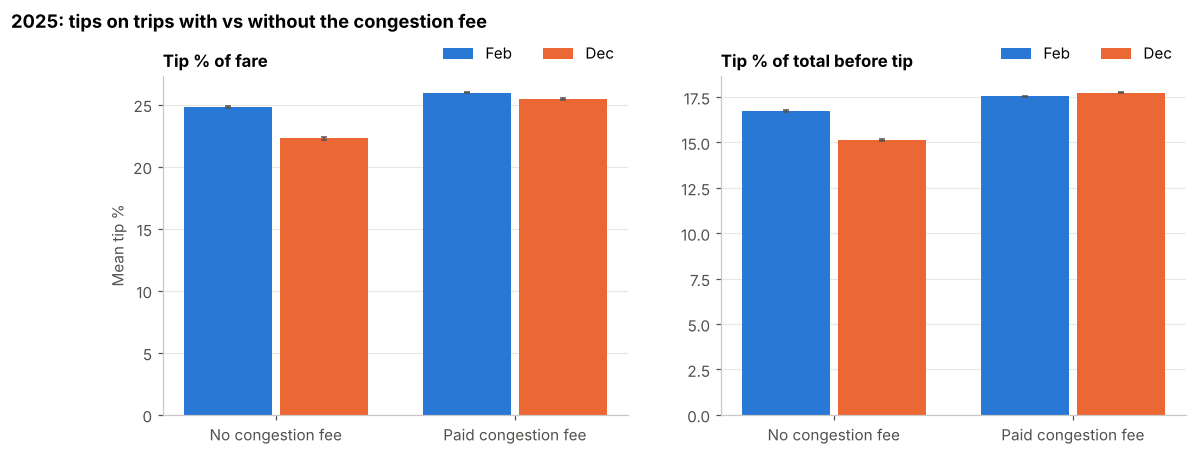

Full-data numbers (tip % of fare):


,month_name,paid_cbd_fee,n,mean,zero_tip_pct,tip20_pct
0,Feb,False,556748,24.81,9.99,72.60
1,Feb,True,1731573,25.99,4.55,76.78
2,Dec,False,700369,22.23,19.67,65.45
3,Dec,True,1813529,25.49,4.93,77.02


In [10]:
s25 = sample[sample.year == tu.TEST_YEAR].copy()
s25["fee"] = s25.paid_cbd_fee.map({True: "Paid congestion fee", False: "No congestion fee"})
rows = []
for col, label in [("tip_pct", "Tip % of fare"), ("tip_pct_total", "Tip % of total before tip")]:
    t = s25.groupby(["fee", "month_name"])[col].agg(["mean", "std", "size"]).reset_index()
    t["ci95"] = 1.96 * t["std"] / np.sqrt(t["size"])
    t["measure"] = label
    rows.append(t)
cbd = pd.concat(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label in zip(axes, ["Tip % of fare", "Tip % of total before tip"]):
    tu.grouped_bar(ax, cbd[cbd.measure == label], "fee", "month_name", "mean", tu.MONTH_COLORS,
                   err="ci95", order=["No congestion fee", "Paid congestion fee"], groups=MONTHS2)
    ax.set_title(label, fontsize=11)
axes[0].set_ylabel("Mean tip %")
fig.suptitle("2025: tips on trips with vs without the congestion fee", x=0.01, ha="left",
             fontweight="bold", y=1.03)
tu.save_fig(fig, "07c_congestion_fee")
plt.show()

print("Full-data numbers (tip % of fare):")
full_cbd[["month_name", "paid_cbd_fee", "n", "mean", "zero_tip_pct", "tip20_pct"]]

## 7d · Notes for the report (fill in after running)

* **Stable patterns (Step 6):** …
* **Patterns that change between years:** …
* **How 2025 differs:** payment type 0 share, zero-tip share, congestion fee, missing passenger counts …
* **What this means for using 2025 as the test set:** …
* **Decisions for modeling:** tip % denominator, classification threshold, features to keep or drop (`passenger_count`, `cbd_congestion_fee`) …